Robert Shanahan - 23380039
Adam Downes - 23358173
Philip Roche - xx

Does our code work

Third party implementations used:
- Tensorflow agents: https://www.geeksforgeeks.org/machine-learning/reinforcement-learning-with-tensorflow-agents/
- Help: https://chloeewang.medium.com/using-deep-reinforcement-learning-to-play-atari-space-invaders-8d5159aa69ed
- Lecture: https://learn.ul.ie/d2l/le/lessons/91713/topics/1450952 

# Why Reinforcement Learning is the machine learning paradigm of choice for this task
- Training an ML agent to play *Space Invaders* requires reinforcement learning since each frame cannot be labeled as good or bad for supervised learning
- Reinforcement learning allows the agent to explore the environment and figure out the objective function through the environment giving it rewards based on its interations

# Gym Environment

In [19]:
"""
Install pre-requisite packages
"""
%pip install ale-py
import random

import gymnasium as gym
import ale_py
import pygame
import matplotlib.animation
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
import numpy as np
from collections import deque

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
gym.register_envs(ale_py)

env = gym.make("ALE/SpaceInvaders-v5", render_mode="rgb_array") # load our space invaders as a rgb array
observation, info = env.reset() #reset the environment
pygame.init() # initialise pygame for rendering

(5, 0)

### Preprocessing of data

In [3]:
def plot_img(img, figsize=(4, 5.25)):
    plt.figure(figsize=figsize) 
    plt.imshow(img)
    plt.axis("off")
    return img

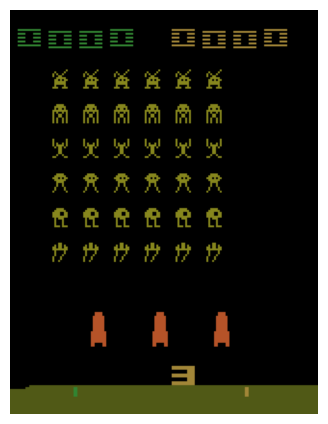

In [4]:
# Define a helper function for creating plots
def plot_environment(env, figsize=(4, 5.25)):
    plt.figure(figsize=figsize)
    img = env.render()
    plt.imshow(img)
    plt.axis("off")
    return img

plot_environment(env) # plot our initial image
plt.show()

In [5]:
envs = gym.envs.registry # envs is a dictionary of all atari games
envs["ALE/SpaceInvaders-v5"] # obtain information on space invaders

EnvSpec(id='ALE/SpaceInvaders-v5', entry_point='ale_py.env:AtariEnv', reward_threshold=None, nondeterministic=False, max_episode_steps=None, order_enforce=True, disable_env_checker=False, kwargs={'game': 'space_invaders', 'repeat_action_probability': 0.25, 'full_action_space': False, 'frameskip': 4, 'max_num_frames_per_episode': 108000}, namespace='ALE', name='SpaceInvaders', version=5, additional_wrappers=(), vector_entry_point='ale_py.vector_env:AtariVectorEnv')

In [6]:
img = env.render() # render a sample scene
img.shape  # height, width, channels (3 = Red, Green, Blue)

(210, 160, 3)

In [7]:
obs, info = env.reset(seed=42) # examine our observation scene with a reproducable seed 
obs

array([[[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0]],

       [[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0]],

       [[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0]],

       ...,

       [[80, 89, 22],
        [80, 89, 22],
        [80, 89, 22],
        ...,
        [80, 89, 22],
        [80, 89, 22],
        [80, 89, 22]],

       [[80, 89, 22],
        [80, 89, 22],
        [80, 89, 22],
        ...,
        [80, 89, 22],
        [80, 89, 22],
        [80, 89, 22]],

       [[80, 89, 22],
        [80, 89, 22],
        [80, 89, 22],
        ...,
        [80, 89, 22],
        [80, 89, 22],
        [80, 89, 22]]], shape=(210, 160, 3), dtype=uint8)

In [8]:
env.action_space # examine number of possible actions

Discrete(6)

In [9]:
env.unwrapped.get_action_meanings() # obtain action meanings

['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE']

### Network Structure

In [10]:
def preprocess_state(img):
    img_temp = tf.image.rgb_to_grayscale(img)
    img_temp = tf.image.resize(img, (84, 84))
    return img_temp

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..181.0].


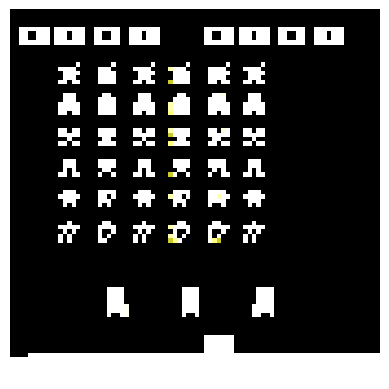

In [11]:
img = env.render()
gray_img = preprocess_state(img)
plt.imshow(tf.squeeze(gray_img), cmap="gray")  # drop the channel dim, use a grey colour map
plt.axis('off')
plt.show()



In [12]:
img.shape

(210, 160, 3)

#### Frame Stacking

In [ ]:
def combine_images(img1, img2, m=4):
    img1, img2 = np.squeeze(img1), np.squeeze(img2)
    if img1.ndim == 3 and img1.shape[2] == m:                     # existing stack (H, W, m)
        im = np.append(img1[:, :, 1:], img2[:, :, None], axis=2)  # drop oldest, add newest
    else:                                                         # first frame (H, W)
        im = np.stack([img1] * m, axis=2)
    return tf.expand_dims(im, 0)                                  # (1, H, W, m)

### Implementation

In [14]:
gray_img.shape

TensorShape([84, 84, 3])

In [15]:
env.action_space.n

np.int64(6)

In [23]:
N_OUTPUTS = 6
EPOCHS = 100
EPSILON = 0.01
EPSILON_DECAY = 0.9
THRESHOLD = 9000
EPSILON_MIN = 0.001
LEARNING_RATE = 0.1

In [ ]:
def build_model(height, width, channels, action_size, alpha, alpha_decay, seed=42):
  
    tf.random.set_seed(seed)  # extra code – ensures reproducibility on the CPU
    # input = (84,84,3)

    model = tf.keras.Sequential([
        layers.Input(shape=(height, width, channels)),
        layers.Conv2D(32, kernel_size=8, strides=4, activation='elu', padding='valid'),
        layers.Conv2D(64, kernel_size=4, strides=2, activation='elu', padding='valid'),
        layers.MaxPooling2D(),
        layers.Conv2D(64, kernel_size=3, strides=1, activation='elu', padding='valid'),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(256, activation="elu"),
        layers.Dense(action_size, activation='linear')
    ])
    
    lr_schedule = optimizers.schedules.InverseTimeDecay(
        initial_learning_rate=alpha, decay_steps=1, decay_rate=alpha_decay
    )
    model.compile(loss='mse', optimizer=optimizers.Adam(learning_rate=lr_schedule))

    return model

In [32]:
def build_target_model(model):
    target = models.clone_model(model)
    target.set_weights(model.get_weights())
    return target

In [29]:
def choose_action(state, epsilon=0.1): #epsilon is the probability of exploring a random action
    if np.random.rand() < epsilon:
        return np.random.randint(N_OUTPUTS)  # random action
    else:
        Q_values = model.predict(state[np.newaxis], verbose=0)[0]
        return Q_values.argmax()  # optimal action according to the DQN

In [33]:
def replay(batch_size, memory):
    if len(memory) < batch_size:
        return

In [ ]:
model = build_model(84, 84, 4, 6, LEARNING_RATE, 0.5)
model_target = build_target_model(model)

In [34]:
# TODO FIX 
def train(self):
    scores = deque(maxlen=100)
    avg_scores = []
    memory = []
    for e in range(EPOCHS):
        state = env.reset()
        state = preprocess_state(state)
        state = combine_images(state, state)
        done = False
        i = 0
        while not done:
            action = choose_action(state,epsilon)
            next_state, reward, done, _ = env.step(action)
            next_state = preprocess_state(next_state)
            next_state = combine_images(next_state, state)
            #print(next_state.shape)
            memory.append((state, action, reward, next_state, done))
            state = next_state
            epsilon = max(EPSILON_MIN,EPSILON_DECAY*EPSILON)
            i += reward
            
        #while loop finished
        scores.append(i)
        mean_score = np.mean(scores)
        avg_scores.append(mean_score)
        if mean_score >= THRESHOLD:
            print('Solved after {} trials ✔'.format(e))
            return avg_scores
        if e % 5 == 0:
            print('[Episode {}] - Average Score: {}.'.format(e,mean_score))
        model_target.set_weights(model.get_weights())
        replay(1, memory)

# Results

# Evaluation of Results

# Research

# Statement of Work

# Use of AI

# Videos and Plots

# References